# 07 — Verify the paper's saved tables and figures

**Purpose.** Recompute the 20 recorded numerical summaries from their saved source tables,
compare them with the expected values, and verify the released figure files.

**Inputs** `tests/expected_results.json`, `results/paper_tables/`, and the artifact checksum list.

**Outputs** `results/regenerated/paper_consistency_report.csv`.

These cells verify the saved source tables and figure files. Model fitting is covered
separately in notebook 08; the checks here leave the recorded results unchanged.

The final cells display PNG previews rendered from the unchanged canonical PDFs. The PDFs remain the authoritative figure files.


In [1]:
import os, sys
from pathlib import Path
if 'google.colab' in sys.modules:
    from google.colab import drive; drive.mount('/content/drive')
    os.environ.setdefault('PROVICS_ROOT', '/content/drive/MyDrive/provics-recording-aware-evaluation')
else:
    os.environ.setdefault('PROVICS_ROOT', str(Path.cwd().parent))
sys.path.insert(0, os.environ['PROVICS_ROOT'])
from src.utils.paths import project_root
ROOT = project_root(); print('Project folder:', ROOT.name)

# Render compact, readable tables below each cell.
from IPython.display import display
import pandas as pd
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)


Project folder: code


In [2]:
import json, pandas as pd
from src.evaluation.replay import load_settings, verify_artifacts
settings = load_settings()
records = verify_artifacts()
print('released artifacts checked:', len(records))
print('all intact:', all(r['status'] == 'ok' for r in records))
assert all(r['status'] == 'ok' for r in records), 'released artifact checksum mismatch'


released artifacts checked: 67
all intact: True


In [3]:
expected = json.loads((ROOT / 'tests/expected_results.json').read_text())
print('expected-result entries:', len(expected['entries']))
for entry in expected['entries'][:5]:
    print(f"  {entry['id']:<28} {entry['paper']:<22} {entry['expected']}")
print('  ...')


expected-result entries: 20
  delta_cw_range               Sec 5.1 / Fig 2b       [0.149, 0.535]
  m4_delta_cw_range            Sec 5.1                [0.149, 0.176]
  pre_attack_cyber_auc         Sec 5.1                [0.944, 0.998]
  pre_attack_m4_auc            Sec 5.1                [0.763, 0.786]
  membership_probe_auc         Sec 5.1                1.0
  ...


In [4]:
# Recompute each entry from its source artifact and compare within the recorded tolerance.
import sys
sys.path.insert(0, str(ROOT / 'tests'))
from test_10_paper_consistency import _regenerate, _close

rows = []
for entry in expected['entries']:
    actual = _regenerate(entry['id'], ROOT / 'results/paper_tables')
    ok = _close(actual, entry['expected'], entry['tol'])
    rows.append({'id': entry['id'], 'paper': entry['paper'], 'recorded': entry['expected'],
                 'regenerated': actual, 'tolerance': entry['tol'], 'match': ok})
report = pd.DataFrame(rows)
display(report[['id','recorded','regenerated','match']])
print('\nentries matching:', int(report.match.sum()), 'of', len(report))
assert report.match.all(), 'a paper value no longer reproduces'


,id,recorded,regenerated,match
0,delta_cw_range,"[0.149, 0.535]","[0.149, 0.535]",True
1,m4_delta_cw_range,"[0.149, 0.176]","[0.149, 0.176]",True
2,pre_attack_cyber_auc,"[0.944, 0.998]","[0.944, 0.998]",True
3,pre_attack_m4_auc,"[0.763, 0.786]","[0.763, 0.786]",True
4,membership_probe_auc,1.0,1.0,True
5,cyber_only_gap,"[0.54, 0.528, 0.453, 0.39]","[0.54, 0.528, 0.453, 0.39]",True
6,all_view_gap,0.23,0.23,True
7,all_view_occupancy,"[0.93, 0.95]","[0.93, 0.95]",True
8,any_overlap_vs_one_to_one,"[0.963, 0.123]","[0.963, 0.123]",True
9,longest_episode_windows,227,227,True



entries matching: 20 of 20


In [5]:
# The paper now uses a rounded upper bound consistent with the unchanged artifact value.
entry = next(e for e in expected['entries'] if e['id'] == 'buffer_max_shift')
print('paper text :', entry['paper_text'])
print('artifact   :', entry['expected'])
print()
print(entry['reporting_note'])


paper text : changes the median gap by less than 0.009
artifact   : 0.0088

The artifact maximum is 0.008827 at window 30 s / M2. The current paper reports less than 0.009. The expected value remains 0.0088 at four decimal places; only the reporting wording has changed.


In [6]:
# The three canonical figures, with checksums.
from src.utils.hashing import sha256_file
for figure in sorted((ROOT / 'results/paper_figures').glob('*.pdf')):
    print(f'{figure.name:<44} {figure.stat().st_size:>7} B  {sha256_file(figure)[:16]}')
print()
print('These PDFs are the figures compiled into the submitted manuscript. They are canonical',
      'artifacts, not regenerated output.')

out = ROOT / 'results/regenerated'; out.mkdir(parents=True, exist_ok=True)
report.to_csv(out / 'paper_consistency_report.csv', index=False)
print('\nwrote results/regenerated/paper_consistency_report.csv')


figure1_recording_aware_evaluation.pdf         74012 B  0b8ebcf7d30e766b
figure2_window_sensitivity.pdf                 22540 B  8a20cc281097f652
figure3_fusion_and_operational.pdf             17698 B  fc4ab566a91c4c9d

These PDFs are the figures compiled into the submitted manuscript. They are canonical artifacts, not regenerated output.

wrote results/regenerated/paper_consistency_report.csv


### Paper Figure 1: evaluation framework

This is a preview of the saved framework figure, not a new drawing.


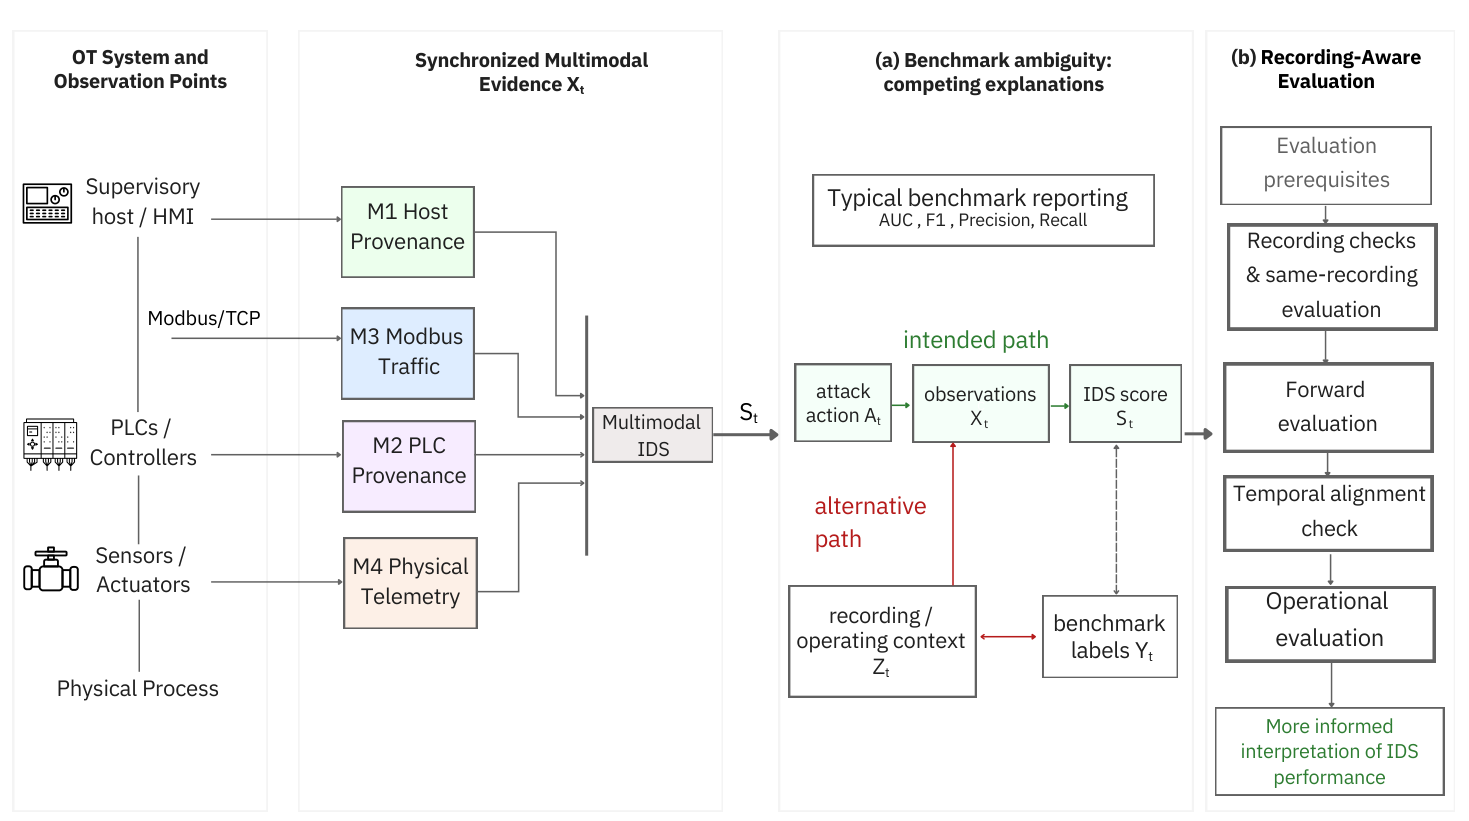

Source: results/paper_figures/figure1_recording_aware_evaluation.pdf


In [7]:
# Render an existing figure for inline display; do not edit or replace its PDF.
import pymupdf
from IPython.display import Image, display
figure_path = ROOT / 'results/paper_figures/figure1_recording_aware_evaluation.pdf'
with pymupdf.open(figure_path) as document:
    preview = document[0].get_pixmap(matrix=pymupdf.Matrix(2, 2), alpha=False)
display(Image(data=preview.tobytes('png'), width=min(1000, preview.width)))
print('Source:', figure_path.relative_to(ROOT).as_posix())

### Paper Figure 2: recording comparisons

This preview uses the existing paper figure. The underlying summary tables are inspected in notebook 03.


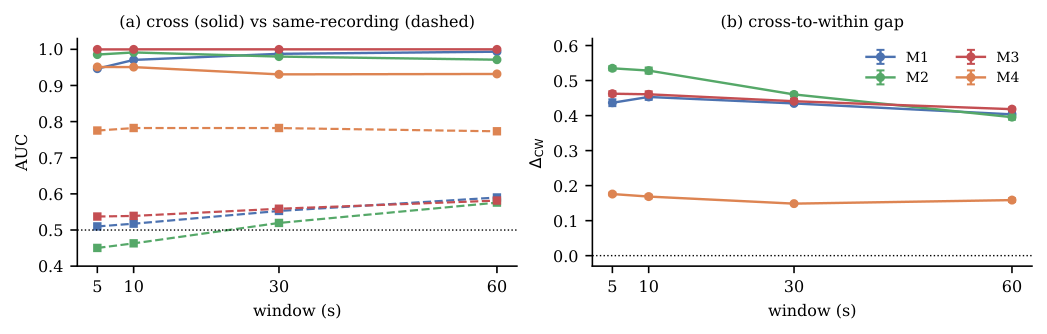

Source: results/paper_figures/figure2_window_sensitivity.pdf


In [8]:
# Render an existing figure for inline display; do not edit or replace its PDF.
import pymupdf
from IPython.display import Image, display
figure_path = ROOT / 'results/paper_figures/figure2_window_sensitivity.pdf'
with pymupdf.open(figure_path) as document:
    preview = document[0].get_pixmap(matrix=pymupdf.Matrix(2, 2), alpha=False)
display(Image(data=preview.tobytes('png'), width=min(1000, preview.width)))
print('Source:', figure_path.relative_to(ROOT).as_posix())

### Paper Figure 3: fusion and alarm behavior

This preview uses the existing paper figure. Notebook 04 walks through the saved fusion and event-matching tables.


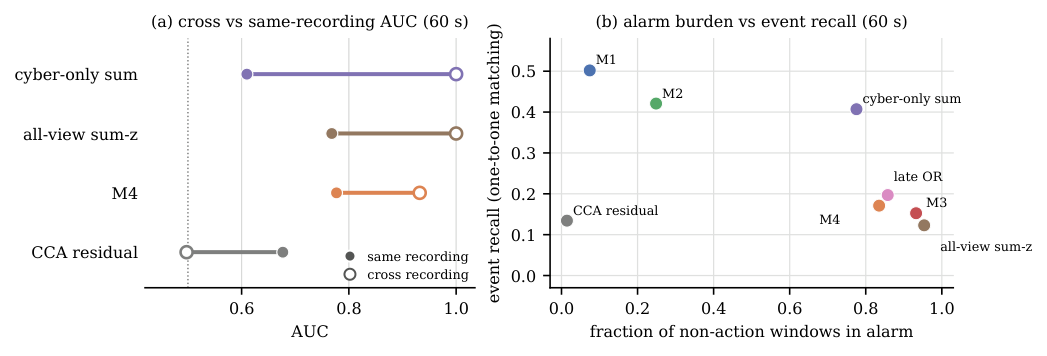

Source: results/paper_figures/figure3_fusion_and_operational.pdf


In [9]:
# Render an existing figure for inline display; do not edit or replace its PDF.
import pymupdf
from IPython.display import Image, display
figure_path = ROOT / 'results/paper_figures/figure3_fusion_and_operational.pdf'
with pymupdf.open(figure_path) as document:
    preview = document[0].get_pixmap(matrix=pymupdf.Matrix(2, 2), alpha=False)
display(Image(data=preview.tobytes('png'), width=min(1000, preview.width)))
print('Source:', figure_path.relative_to(ROOT).as_posix())

## What this notebook checked

- Every listed artifact is present and matches its checksum.
- All 20 expected summaries reproduce from the saved tables within the recorded tolerance.
- The buffer result is unchanged (maximum 0.008827); the paper reports a bound below 0.009.
- The three figure PDFs are verified as saved files, not regenerated.
